# 1. Data profiling, cleaning and linking

Austin Animal Center publishes two separate files: one row per **intake** (an animal arriving) and one row per **outcome** (an animal leaving). Neither answers the questions a shelter cares about on its own, like how long animals stay or how many adoptions get returned. For that I need to connect each intake to its outcome.

This notebook walks through what I found in the raw data, the cleaning rules in `src/clean.py`, and how I checked that the intake-to-outcome matching is right. The pipeline itself runs as a script:

```
python src/clean.py         # clean + link -> data/processed/stays.parquet
python src/build_model.py   # SQL star schema + quality checks -> CSVs for Power BI
```

In [1]:
import sys, os
os.chdir("..")                      # run from the repo root, like the scripts
sys.path.append("src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import clean as C

ACCENT, ACCENT2, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#b4b2a9", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10.5,
    "legend.frameon": False,
})
def save(name):
    plt.tight_layout()
    plt.savefig("images/" + name, bbox_inches="tight", dpi=150)
    plt.show()

## 1.1 Raw files

In [2]:
raw_in = pd.read_csv("data/raw/aac_intakes.csv.gz")
raw_out = pd.read_csv("data/raw/aac_outcomes.csv.gz")
for name, d in [("Intakes", raw_in), ("Outcomes", raw_out)]:
    print(f"{name:<9} rows={len(d):,}  animals={d['Animal ID'].nunique():,}  exact duplicate rows={d.duplicated().sum()}")
raw_in.head(3)

Intakes   rows=173,812  animals=156,287  exact duplicate rows=36
Outcomes  rows=173,775  animals=156,237  exact duplicate rows=26


,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A521520,Nina,10/01/2013 07:51:00 AM,October 2013,Norht Ec in Austin (TX),Stray,Normal,Dog,Spayed Female,7 years,Border Terrier/Border Collie,White/Tan
1,A664235,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
2,A664236,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White


In [3]:
raw_out.head(3)

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green


There are about 156,000 animals but 174,000 intakes, so many animals came through the shelter more than once. That's why I can't simply join the two files on `Animal ID`: an animal with three intakes and three outcomes would produce nine rows.

## 1.2 Problems I found

In [4]:
issues = []
issues.append(("Both", "Exact duplicate rows", raw_in.duplicated().sum() + raw_out.duplicated().sum()))
issues.append(("Intakes", "Date stored as text ('10/01/2013 07:51:00 AM')", len(raw_in)))
fmt = raw_out["DateTime"].str.len()
issues.append(("Outcomes", "Two timestamp formats in one column (with and without '-05:00')", (fmt == 25).sum()))
issues.append(("Both", "Age stored as text ('2 years', '3 weeks')", len(raw_in) + len(raw_out)))
issues.append(("Intakes", "Negative ages ('-1 years')", raw_in["Age upon Intake"].str.startswith("-").sum()))
issues.append(("Intakes", "'1 weeks' and '1 week' both used", (raw_in["Age upon Intake"] == "1 weeks").sum()))
issues.append(("Both", "Sex and spay/neuter status packed into one field", len(raw_in)))
issues.append(("Both", "Breed has 3,000+ values, mixes written as 'A/B' or 'A Mix'", raw_in["Breed"].nunique()))
issues.append(("Outcomes", "Missing outcome type", raw_out["Outcome Type"].isna().sum()))
issues.append(("Intakes", "Missing name (normal: many strays arrive without one)", raw_in["Name"].isna().sum()))
pd.DataFrame(issues, columns=["file", "issue", "rows affected"])

,file,issue,rows affected
0,Both,Exact duplicate rows,62
1,Intakes,Date stored as text ('10/01/2013 07:51:00 AM'),173812
2,Outcomes,Two timestamp formats in one column (with and ...,3584
3,Both,"Age stored as text ('2 years', '3 weeks')",347587
4,Intakes,Negative ages ('-1 years'),10
5,Intakes,'1 weeks' and '1 week' both used,1433
6,Both,Sex and spay/neuter status packed into one field,173812
7,Both,"Breed has 3,000+ values, mixes written as 'A/B...",3006
8,Outcomes,Missing outcome type,46
9,Intakes,Missing name (normal: many strays arrive witho...,49991


In [5]:
print(raw_out.loc[fmt == 25, "DateTime"].str[11:19].value_counts().head(3))

DateTime
00:00:00    3584
Name: count, dtype: int64


The rows with a `-05:00` offset all have a time of midnight, so they're older date-only records. Everything is local Austin time, so I keep the date and time part and drop the offset.

## 1.3 Cleaning rules

| Field | Rule |
|---|---|
| Timestamps | Parse both formats into one datetime type |
| Age | Convert to days (`2 years` → 730.5). Negative ages become missing, then group into Baby / Juvenile / Adult / Senior |
| Sex | Split into `sex` (Male/Female/Unknown) and `fixed` (Fixed/Intact/Unknown) |
| Breed | Flag mixes and keep the first-listed breed as `primary_breed` |
| Color | Keep the first color as `primary_color`, and flag black animals |
| Found location | Pull out the city from "1208 Anise in Austin (TX)" |

In [6]:
for t in ["2 years", "1 weeks", "3 months", "-1 years", "0 years"]:
    print(f"{t!r:>12} -> {C.age_to_days(t)}")

   '2 years' -> 730.5
   '1 weeks' -> 7
  '3 months' -> 91.32000000000001
  '-1 years' -> nan
   '0 years' -> 0.0


## 1.4 Linking each intake to its outcome

For every intake, I take the **first outcome for the same animal that happens after it**, but only if it comes before that animal's next intake. If it doesn't, the stay has no recorded outcome. `pd.merge_asof` does the "first one after" part efficiently.

In [7]:
intakes = C.load_intakes()
outcomes = C.load_outcomes()
stays = C.add_features(C.link_stays(intakes, outcomes), outcomes["outcome_at"].max())
print(f"Stays: {len(stays):,}   with an outcome: {stays['has_outcome'].mean():.1%}")

Stays: 173,776   with an outcome: 99.1%


In [8]:
# A worked example: an animal that came in four times
busy = stays["animal_id"].value_counts()
example = busy[busy == 4].index[0]
stays.loc[stays["animal_id"] == example,
          ["animal_id", "stay_number", "intake_at", "intake_type", "outcome_at", "outcome_type", "length_of_stay_days"]]

,animal_id,stay_number,intake_at,intake_type,outcome_at,outcome_type,length_of_stay_days
339,A430709,1,2017-03-02 09:08:00,Stray,2017-03-06 17:20:00,Return to Owner,4.341667
340,A430709,2,2017-12-26 08:18:00,Stray,2017-12-30 16:04:00,Return to Owner,4.323611
341,A430709,3,2018-04-29 16:25:00,Stray,2018-05-02 12:59:00,Return to Owner,2.856944
342,A430709,4,2018-07-25 16:30:00,Stray,2018-08-08 16:38:00,Transfer,14.005556


### Checking the matching

Every check below should be zero. The same checks run in SQL during the build (`sql/02_data_quality_checks.sql`), and the build stops if any fail.

In [9]:
nxt = stays.groupby("animal_id")["intake_at"].shift(-1)
checks = {
    "outcome before its intake": (stays["outcome_at"] < stays["intake_at"]).sum(),
    "outcome after the next intake": (stays["outcome_at"] > nxt).sum(),
    "one outcome used by two stays": stays.dropna(subset=["outcome_at"]).duplicated(["animal_id", "outcome_at"]).sum(),
}
pd.Series(checks, name="failing rows")

outcome before its intake        0
outcome after the next intake    0
one outcome used by two stays    0
Name: failing rows, dtype: int64

In [10]:
unmatched = stays[~stays["has_outcome"]]
by_year = unmatched.groupby(unmatched["intake_at"].dt.year).size()
by_year

intake_at
2013      2
2014     54
2015     66
2016     63
2017    127
2018    115
2019    116
2020     45
2021     21
2022     29
2023     36
2024    147
2025    817
dtype: int64

**1,638 stays (0.9%) have no outcome.** Over half are from 2025, which are mostly animals that were still in the shelter when the data was exported in May 2025. The rest are older records where the outcome was never logged. I keep them, flag them, and leave them out of length-of-stay and outcome rates.

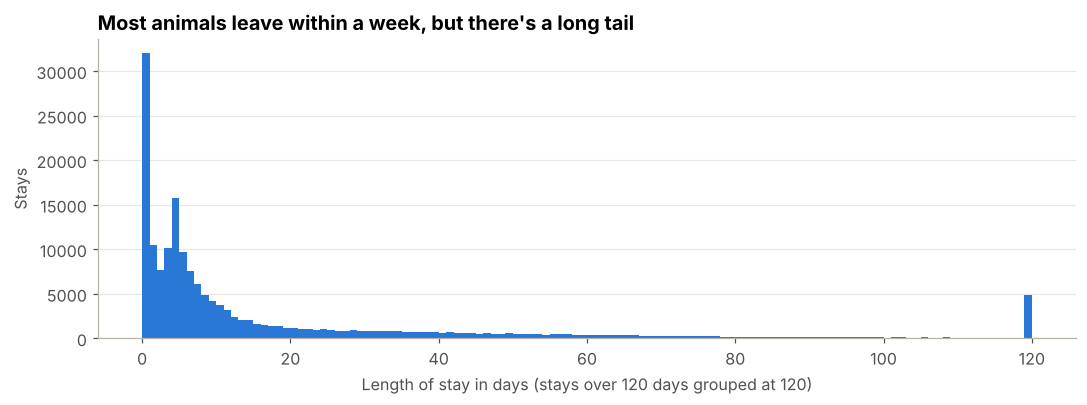

median 6.0 days | mean 21.1 days | 90th percentile 56 days | over a year: 577


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
los = stays["length_of_stay_days"].dropna()
ax.hist(los.clip(upper=120), bins=120, color=ACCENT)
ax.set_title("Most animals leave within a week, but there's a long tail")
ax.set_xlabel("Length of stay in days (stays over 120 days grouped at 120)")
ax.set_ylabel("Stays")
ax.grid(axis="x", visible=False)
save("01_length_of_stay_distribution.png")
print(f"median {los.median():.1f} days | mean {los.mean():.1f} days | 90th percentile {los.quantile(.9):.0f} days | over a year: {(los > 365).sum()}")

Length of stay is heavily skewed (mean 21 days vs median 6), so I report **medians** throughout and in the dashboard.

## 1.5 Output

`data/processed/stays.parquet` has one row per stay with clean types and the new fields. `src/build_model.py` turns it into a star schema for Power BI:

- `fact_stay`: one row per stay (dates, length of stay, outcome flags)
- `dim_animal`: one row per animal (type, breed, color, sex)
- `dim_intake_type`, `dim_outcome_type`: intake and outcome categories plus groupings
- `dim_date`: a calendar table

The analysis continues in `02_analysis.ipynb`.